# PHYS 763 HW4b: From IQ Blobs to Readout Errors
Fall 2026 - due Monday, November 2, 2026. **15 points**, separate from written HW4.

Use the settings and local-state checkpoint procedure in the PDF handout to collect IQ data from two working qubits. Start QUAlibrate with `uv run qualibrate start` and access its browser interface at http://127.0.0.1:8001 (the default address). Run `07_iq_blobs`, one selected qubit at a time, with 1000 shots per preparation class.

This notebook analyzes your saved runs. Use the Qolab Python environment as your notebook kernel. Complete the plots, classifier, and written answers below.

In [49]:
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

## 1. IQ clouds and experimental record (4 points)

Submit your raw datasets, saved run parameters, and completed notebook with answers to every part of the PDF. Keep tokens and credentials out of the submission.

| Qubit | Run ID | Date/time | Commit | Shots per class | Reset mode | Local checkpoint/restoration |
| --- | --- | --- | --- | --- | --- | --- |
| Q5 | 221221 | 2026-10-26 22:12:21 | 63f10b | 1000 | thermal | state-hw4b-start-20261026_220824.quamstore |
| Q6 | 221304 | 2026-10-26 22:13:04 | 63f10b | 1000 | thermal | state-hw4b-start-20261026_220824.quamstore |

Explain the two preparation sequences. The labels g/e identify the intended preparation.

Each run saves `ds_raw.h5` in the project's data directory, under `qualibration_graphs/superconducting/calibrations/1Q_calibrations/data/`. Load this file for your analysis. Restore the saved starting state after each acquisition as described in the handout.

The raw IQ variables are **Ig, Qg, Ie, Qe**, indexed by **qubit** and **n_runs**. They are individual integrated samples, already in **volts**, even when unit metadata are absent. Multiply all coordinates by 1000 if plotting in millivolts.

In [50]:
def load_iq(path):
    """Load a current 07_iq_blobs raw dataset; no hardware imports."""
    path = Path(path).expanduser()
    if not path.is_file():
        raise FileNotFoundError(f"Choose the ds_raw.h5 from your saved IQ run: {path}")
    with xr.open_dataset(path) as opened:
        ds = opened.load()
    required = {"Ig", "Qg", "Ie", "Qe"}
    if not required.issubset(ds.data_vars) or "qubit" not in ds.coords:
        raise ValueError("Expected Ig, Qg, Ie, Qe and named qubits from 07_iq_blobs.")
    return ds


def iq_samples(ds, qubit):
    """Return arrays of shape (number of shots, 2), with columns I and Q in V."""
    if qubit not in ds.qubit.values:
        raise ValueError(f"Unknown qubit {qubit!r}; choose from {ds.qubit.values.tolist()}")
    selected = ds.sel(qubit=qubit)
    values = {}
    for name in ("Ig", "Qg", "Ie", "Qe"):
        da = selected[name]
        if da.dims != ("n_runs",):
            raise ValueError(f"{name}: expected single-shot n_runs dimension; found {da.dims}")
        units = str(da.attrs.get("units", "")).strip().lower()
        if units not in ("", "v", "volt", "volts"):
            raise ValueError(f"{name}: unexpected units {units!r}; inspect the source before converting.")
        values[name] = np.asarray(da.values, dtype=float)
    if len({a.shape for a in values.values()}) != 1:
        raise ValueError("The four IQ arrays have different shapes.")
    if not all(np.isfinite(a).all() for a in values.values()):
        raise ValueError("Non-finite IQ values: inspect the run before deciding how to handle them.")
    if len(values["Ig"]) < 4:
        raise ValueError("At least four samples per class are needed for this split.")
    return (np.column_stack((values["Ig"], values["Qg"])),
            np.column_stack((values["Ie"], values["Qe"])))


def split_iq(xy_g, xy_e, seed=763):
    """Split shot-pair indices 50/50, using the same indices in both classes."""
    xy_g = np.asarray(xy_g, dtype=float)
    xy_e = np.asarray(xy_e, dtype=float)
    if xy_g.shape != xy_e.shape or xy_g.ndim != 2 or xy_g.shape[1] != 2:
        raise ValueError("Expected equally sized (N, 2) arrays for g and e.")
    if len(xy_g) < 4 or not (np.isfinite(xy_g).all() and np.isfinite(xy_e).all()):
        raise ValueError("Need at least four finite samples in each class.")
    order = np.random.default_rng(seed).permutation(len(xy_g))
    train = order[:len(order) // 2]
    test = order[len(order) // 2:]
    return {
        "train_g": xy_g[train], "train_e": xy_e[train],
        "test_g": xy_g[test], "test_e": xy_e[test],
        "train_indices": train, "test_indices": test,
    }

## Load your two runs
Set each saved-run path and qubit label below, using the names listed in the dataset (for example, Q1). The two qubits can come from different saved run files.

In [51]:
# return full data file path from a run
def get_full_path(run_name):
    return 'data/2026-10-26/' + run_name + '/ds_raw.h5'

RUNS = [
    {"path": get_full_path("#15_07_iq_blobs_221221"), "qubit": "Q5"},
    {"path": get_full_path("#16_07_iq_blobs_221304"), "qubit": "Q6"}
]

samples = {}
splits = {}
for run in RUNS:
    if run["path"] is None:
        continue
    ds = load_iq(run["path"])
    print("Run:", run["path"])
    print("Qubit labels:", ds.qubit.values.tolist())
    display(ds)
    if run["qubit"] is None:
        print("Select a qubit label in RUNS, then rerun this cell.")
        continue
    qubit = run["qubit"]
    if qubit in samples:
        raise ValueError("Choose two distinct qubits for this assignment.")
    samples[qubit] = iq_samples(ds, qubit)
    splits[qubit] = split_iq(*samples[qubit])
    print(qubit, "samples per class:", len(samples[qubit][0]),
          "training:", len(splits[qubit]["train_g"]),
          "test:", len(splits[qubit]["test_g"]))

if not samples:
    print("Enter your saved IQ paths and qubit names in RUNS to begIn.")

Run: data/2026-10-26/#15_07_iq_blobs_221221/ds_raw.h5
Qubit labels: ['Q5']


<xarray.Dataset> Size: 40kB
Dimensions:  (qubit: 1, n_runs: 1000)
Coordinates:
  * qubit    (qubit) <U2 8B 'Q5'
  * n_runs   (n_runs) float64 8kB 1.0 2.0 3.0 4.0 ... 997.0 998.0 999.0 1e+03
Data variables:
    Ig       (qubit, n_runs) float64 8kB 0.000692 0.0005492 ... 7.117e-05
    Qg       (qubit, n_runs) float64 8kB -0.0002054 -5.541e-05 ... -0.0002452
    Ie       (qubit, n_runs) float64 8kB 0.0007561 0.0007186 ... 0.0008885
    Qe       (qubit, n_runs) float64 8kB -0.0002683 -0.0005051 ... -0.000346

Q5 samples per class: 1000 training: 500 test: 500
Run: data/2026-10-26/#16_07_iq_blobs_221304/ds_raw.h5
Qubit labels: ['Q6']


<xarray.Dataset> Size: 40kB
Dimensions:  (qubit: 1, n_runs: 1000)
Coordinates:
  * qubit    (qubit) <U2 8B 'Q6'
  * n_runs   (n_runs) float64 8kB 1.0 2.0 3.0 4.0 ... 997.0 998.0 999.0 1e+03
Data variables:
    Ig       (qubit, n_runs) float64 8kB 0.0004295 0.0004126 ... 0.0002784
    Qg       (qubit, n_runs) float64 8kB -0.0002749 -0.0005613 ... -0.0006615
    Ie       (qubit, n_runs) float64 8kB 0.001129 0.001124 ... 0.001288
    Qe       (qubit, n_runs) float64 8kB -0.0005726 -0.00095 ... -0.000719

Q6 samples per class: 1000 training: 500 test: 500


### 1(b): plot and inspect
Make one equal-axis IQ scatter plot for each qubit, overlaying g/e preparation classes. Label units. Comment on separation, overlap, and visible tails or outliers. This overview can use all samples; use only the training split to choose the classifier.

**1(a): preparation sequences and experimental record:**

**Answer** The ground state |g> is prepared by thermal reset. The excited state |e> is prepared by applying an x180 pulse drive after thermal reset.

**1(b): observations:**

**Answer** Qubit 6 has better separation between the |g> and |e> IQ clouds, with less overlap. Both qubits have outliers that extend well into the region occupied by the other state.

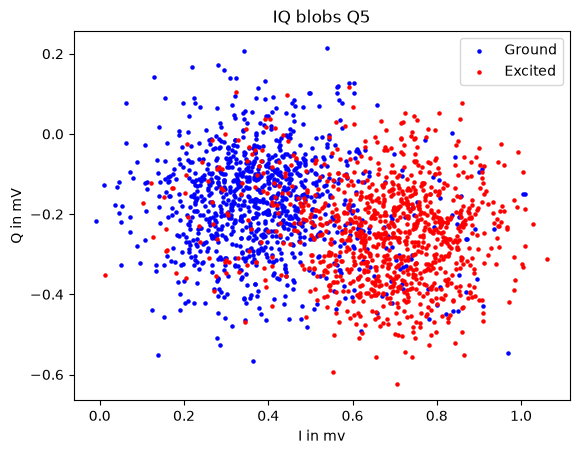

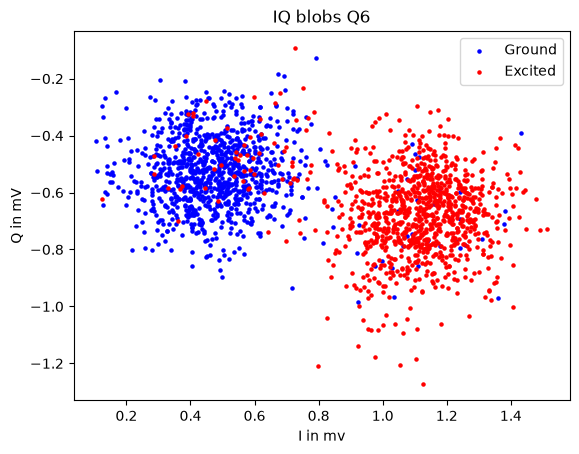

In [52]:
def load_data(path, qubit, onlyTrain=0, onlyTest=0) :
    ds=load_iq(path)
    (g,e)=iq_samples(ds,qubit)
    g=g*1000 #convert to mv
    e=e*1000
    if onlyTrain:
        return (g[:500,0],g[:500,1],e[:500,0],e[:500,1])
    elif onlyTest:
        return (g[-500:,0],g[-500:,1],e[-500:,0],e[-500:,1])
    else:
        return (g[:,0],g[:,1],e[:,0],e[:,1])
    
    
# Write your IQ plotting code here.
def plot_one(path, qubit, dotsize) :
    (gI,gQ,eI,eq)=load_data(path,qubit)
     
    # Create scatter plots in mv
    plt.scatter(gI, gQ,color='blue', s=dotsize,label='Ground')
    plt.scatter(eI, eq,color='red', s=dotsize, label='Excited')
    
    # Add labels and title
    plt.xlabel("I in mv")
    plt.ylabel("Q in mV")
    plt.title("IQ blobs " +qubit)
    
    # Display the plot
    plt.legend()
    plt.show()
dotsize=5
for run in RUNS:
    plot_one(run["path"],run["qubit"],dotsize)

## 2. Build and evaluate a discriminator (7 points)

### 2(a): choose a projection (2 points)
Use each qubit's **training** centroids to construct an angle theta so that `x = I*cos(theta) + Q*sin(theta)` lies along their separation, with the e centroid at larger x. Explain the construction and report theta. Use `splits[qubit]['train_g']` and `splits[qubit]['train_e']` to fit the rule; keep it fixed on the test data.

**Construction and angles:**

In [53]:
# Compute the training centroids and discrimination axis for each qubit.
# the parameters are data for ground I, ground Q, excited I, excited Q

def comp_centroids_theta(gI,gQ,eI,eQ):
    gI_avg = np.mean(gI)
    gQ_avg = np.mean(gQ)
    eI_avg = np.mean(eI)
    eQ_avg = np.mean(eQ)
    theta = np.arctan2(eQ_avg-gQ_avg, eI_avg-gI_avg)
    return (theta,gI_avg,gQ_avg,eI_avg,eQ_avg)
    
def print_centroids_theta(path, qubit):
    gI, gQ, eI, eQ = load_data(path, qubit,0)
    (theta,gI_avg,gQ_avg,eI_avg,eQ_avg)=comp_centroids_theta(gI,gQ,eI,eQ)
    print(f"\nQubit {qubit}")
    print(f"Ground centroid  = ({gI_avg}, {gQ_avg})")
    print(f"Excited centroid  = ({eI_avg}, {eQ_avg})")
    print(f"theta = {theta}")
    return

for run in RUNS:
    print_centroids_theta(run["path"],run["qubit"])
    


Qubit Q5
Ground centroid  = (0.39303404998779295, -0.17440069580078124)
Excited centroid  = (0.6704523239135742, -0.2468551559448242)
theta = -0.25546747363834194

Qubit Q6
Ground centroid  = (0.4898628997802734, -0.533719825744629)
Excited centroid  = (1.0859023666381835, -0.6680034408569336)
theta = -0.22159345895376978


**2(a) Answer**: We first take the average of I/Q data for g and e, and then use $arctan(\frac{eQ_{avg}-gQ_{avg}}{eI_{avg}-gI_{avg}})$ to get $\theta$

### 2(b): choose and apply the threshold (2 points)
Assign e for `x >= t`, and g otherwise. Minimize the training balanced error defined in the handout. A search over intervals between sorted distinct projected values, plus the constant-classifier limits, is sufficient. Explain your search and handling of ties.

Project the test data along the **fixed training axis** and make overlaid test histograms, marking the **fixed training threshold**. Report threshold units.

**Threshold method and values:**


Qubit Q5.  All these numbers are calculated from training data
theta  = -0.25907329007943736
Threshold  = 0.5518960412034762
Confusion matrix: 
 [[0.854 0.146]
 [0.134 0.866]]
F_assign = 0.86


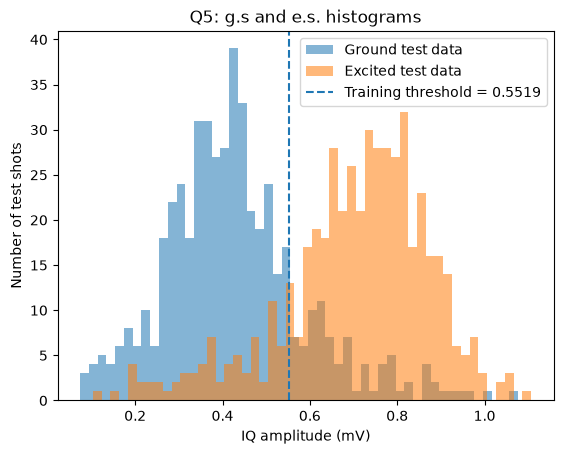


Qubit Q6.  All these numbers are calculated from training data
theta  = -0.21304633140946014
Threshold  = 0.8915492143229891
Confusion matrix: 
 [[0.972 0.028]
 [0.072 0.928]]
F_assign = 0.95


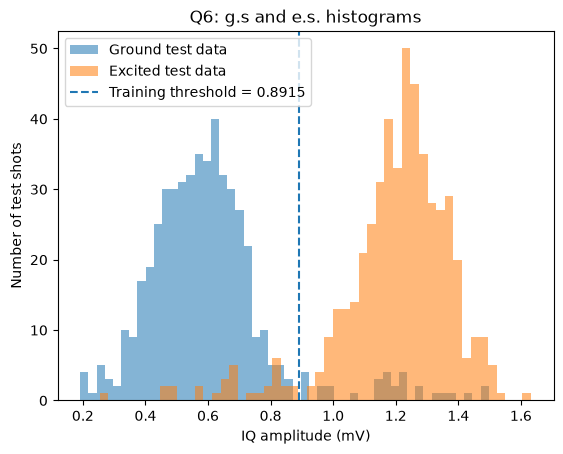

In [54]:
# Fit thresholds using training samples; plot held-out histograms.
import bisect
#get projection array from I/Q arrays using theta
def get_projection(I,Q,theta):
    return I*np.cos(theta)+Q*np.sin(theta)
    
def get_threshold(path,qubit,onlyTrain):
    gI, gQ, eI, eQ = load_data(path, qubit,onlyTrain)
    shots=gI.size;
    theta,*_=comp_centroids_theta(gI,gQ,eI,eQ)
    g_proj=sorted(get_projection(gI,gQ,theta))
    e_proj=sorted(get_projection(eI,eQ,theta))
    
    values = np.unique(g_proj+e_proj)   #sorted, unique, projected values
    values = np.concatenate(([values[0]-0.1], (values[:-1]+values[1:])/2, [values[-1]+0.1]))  # take average of two adjacent values, and then add 1 smaller than all, 1 larger than all.
    
    balance_error=1
    for value in values:
        g_report_e=(shots-bisect.bisect_left(g_proj,value))/shots
        e_report_g=bisect.bisect_left(e_proj,value)/shots
        cur_error=(g_report_e+e_report_g)/2
        if cur_error<balance_error:
            threshold=value
            max_threshold=value
            update_max=1
            balance_error=cur_error
            #print(f"\nbalance error ={balance_error}, threshold = {threshold}, confusions= {g_report_e} {e_report_g}")
        elif cur_error>balance_error:
            update_max=0
        elif update_max:   #if consecutive thresholds have identical minimum balance errors, we record both min threshold and max threshold
            max_threshold=value
    threshold=(threshold+max_threshold)/2
    g_report_e=(shots-bisect.bisect_left(g_proj,threshold))/shots
    e_report_g=bisect.bisect_left(e_proj,threshold)/shots
    return (threshold, theta, g_report_e, e_report_g)
    
def print_threshold(threshold, theta, g_report_e, e_report_g,shot_total=0):
    print(f"theta  = {theta}")
    print(f"Threshold  = {threshold}")
    if shot_total>0:
        print(f"Total shots = {shot_total} for each of g and e ")
        print(f"g reported as e count = {int(g_report_e*shot_total)}")
        print(f"e reported as g count = {int(e_report_g*shot_total)}")
    print(f"Confusion matrix: \n {np.array([[1-g_report_e, g_report_e],[e_report_g,1-e_report_g]])}")
    print(f"F_assign = { 1-(g_report_e+e_report_g)/2}")
    return (threshold, theta)
    
def plot_threshold_and_histogram(path, qubit):
    #calculate threshold and theta from training data
    (threshold, theta, g_report_e, e_report_g)=get_threshold(path,qubit,1)   #passing 0 as third parameter of get_threshold call will reproduce qualibrate's calculations 
    print(f"\nQubit {qubit}.  All these numbers are calculated from training data")
    print_threshold(threshold, theta, g_report_e, e_report_g)

    #plot histograms using test data
    gI, gQ, eI, eQ = load_data(path, qubit, 0, 1)
    g_test_proj = get_projection(gI,gQ,theta)
    e_test_proj = get_projection(eI,eQ,theta)

    plt.hist(g_test_proj, bins=50, alpha=0.55, label="Ground test data")
    plt.hist(e_test_proj, bins=50, alpha=0.55, label="Excited test data")

    plt.axvline(threshold, linestyle="--", label=f"Training threshold = {threshold:.4f}")
    
    plt.xlabel("IQ amplitude (mV)")
    plt.ylabel("Number of test shots")
    plt.title(f"{qubit}: g.s and e.s. histograms")
    plt.legend()
    plt.show()
    
for run in RUNS:
#run=RUNS[1]
    plot_threshold_and_histogram(run["path"],run["qubit"])

**2(b) Answer**

- First, we determine $\theta$ using the training data, following the method described in 2(a).
- We project each ground-state |g> and excited-state |e> IQ sample onto an $x=I*cos(\theta)+Q*sin(\theta)$, obtaining two arrays: g_proj and e_proj.
- We combine the two arrays, sort the values, and remove duplicates to obtain an array containing all unique projected values.
- We generate candidate thresholds by calculating the midpoints between adjacent unique projected values. We also include two additional candidates: one below the minimum projection (\(min - 0.1) and one above the maximum projection (max + 0.1).
- We evaluate each candidate threshold and select the one that minimizes the balanced assignment error. For each candidate:
    - We calculate the probability of incorrectly reporting |e> for a |g> shot by dividing the number of ground-state projections above the threshold, $N_{g\to e}$, by the total number of ground-state shots, $N_g$.
    - Similarly, we calculate the probability of incorrectly reporting |g> for an |e> shot by dividing $N_{e\to g}$ by the total number of excited-state shots, $N_e$.
    - We calculate the balanced assignment error as the average of these two error probabilities.
    - If multiple consecutive candidate thresholds share the same minimum balanced assignment error, we use
    -  the average of the first and last of those thresholds.


### 2(c): confusion matrix and assignment performance (3 points)
For each qubit, report held-out g-to-e and e-to-g error counts and the sample count in each class. Construct the matrix with **rows = intended preparation [g, e]** and **columns = reported state [g, e]**, normalizing each row separately. Calculate the average of its diagonal entries.

Compare your held-out result with the node's all-data fit/evaluation. The node's `readout_fidelity` is a percentage, while its confusion matrix entries are probabilities.

**Results and comparison:**

In [55]:
# Compute error counts, row-normalized matrices, and assignment accuracies.
F_ASSIGN={}
def print_confusion_matrix(path, qubit):
    for matchQualibrateResults in range(2):
        if matchQualibrateResults:
            threshold, theta, *_ = get_threshold(path,qubit,0)  #all data
            gI, gQ, eI, eQ = load_data(path, qubit)  #all data
        else:
            threshold, theta, *_ = get_threshold(path,qubit,1)  #training data
            gI, gQ, eI, eQ = load_data(path, qubit, 0, 1)    #test data
            
        g_proj = get_projection(gI,gQ,theta)
        e_proj = get_projection(eI,eQ,theta)
    
        shots=g_proj.size
        g_report_e=np.sum(g_proj>=threshold)/shots
        e_report_g=np.sum(e_proj<threshold)/shots
        if matchQualibrateResults:
            note="Use the entire dataset to determine theta and the threshold, then calculate the confusion matrix and fidelity."
        else:
            note="Use the training data to determine theta and the threshold, then use the test data to calculate the confusion matrix and fidelity."
            F_ASSIGN[qubit]=1-(g_report_e+e_report_g)/2   #save this to be used in 3a)
            
        print(f"\n{qubit}. {note}")
        print_threshold(threshold, theta, g_report_e, e_report_g,shots)
        # print(f"g projection mean = {np.mean(g_proj)}")
        # print(f"e projection mean = {np.mean(e_proj)}")
    
for run in RUNS:
    print_confusion_matrix(run["path"],run["qubit"])


Q5. Use the training data to determine theta and the threshold, then use the test data to calculate the confusion matrix and fidelity.
theta  = -0.25907329007943736
Threshold  = 0.5518960412034762
Total shots = 500 for each of g and e 
g reported as e count = 84
e reported as g count = 78
Confusion matrix: 
 [[0.832 0.168]
 [0.156 0.844]]
F_assign = 0.838

Q5. Use the entire dataset to determine theta and the threshold, then calculate the confusion matrix and fidelity.
theta  = -0.25546747363834194
Threshold  = 0.5534311736823606
Total shots = 1000 for each of g and e 
g reported as e count = 155
e reported as g count = 146
Confusion matrix: 
 [[0.845 0.155]
 [0.146 0.854]]
F_assign = 0.8495

Q6. Use the training data to determine theta and the threshold, then use the test data to calculate the confusion matrix and fidelity.
theta  = -0.21304633140946014
Threshold  = 0.8915492143229891
Total shots = 500 for each of g and e 
g reported as e count = 30
e reported as g count = 30
Confusi

**2(c) Answer** In the report above, we try to reproduce Qolab's results by using the entire dataset to determine $\theta$ and the threshold, and then using the same dataset to calculate the confusion matrix and $F_{assign}. We obtain results identical to those reported by the Qolab node.

Comparing $F_{assign}$ obtained using the two approaches, we find that using the entire dataset gives us a slightly better $F_{assign}$. This is expected because the test data are also used to determine $\theta$ and threshold, allowing them to be optimized for the entire dataset. 

## 3. Connect to readout physics (4 points)

### 3(a) (2 points)
Using test projections and the fixed axis, compute the mean separation divided by the square root of the sum of the two sample variances. In NumPy, use `np.var(..., ddof=1)` for each sample variance. Report this SNR alongside assignment accuracy for both qubits.

Relate the mean separation to written HW4's state-dependent resonator response. Why is raw separation alone insufficient to rank readout? Does rotating stored IQ data change the physical measurement?

**Answer:** The raw IQ data for the g/e states recorded by Qolab correspond to the integrated weighted signal outputs discussed in HW4. Projecting the IQ data using $x=I*cos(\theta)+Q*sin(\theta)$ is equivalent to the $Re(e^{-i\theta}*(I+iQ))$.

Raw mean separation alone is insufficient to rank readout performance because it does not account for noise. Even if the two states have well-separated means, large variances can cause their projected distributions to overlap, increasing assignment errors and reducing the SNR.

Rotating the stored IQ data is a post-processing operation that makes reporting and analysis more intuitive, and it also makes state assignment to be based on a single number rather than two coordinates.  But it doesn't change the physical measurement.

In [56]:
# Calculate held-out SNRs and summarize the results for the two qubits.
def print_SNR(path, qubit):
    threshold, theta, *_ = get_threshold(path,qubit,1)  #training data
    gI, gQ, eI, eQ = load_data(path, qubit, 0, 1)    #test data
        
    g_test_proj = get_projection(gI,gQ,theta)
    e_test_proj = get_projection(eI,eQ,theta)

    g_mean=np.mean(g_test_proj)
    e_mean=np.mean(e_test_proj)

    g_var=np.var(g_test_proj,ddof=1)
    e_var=np.var(e_test_proj,ddof=1)
    
    print(f"\n{qubit}") 
    print(f"Centroid seperation = {e_mean-g_mean}")
    print(f"g sample variance = {g_var}")
    print(f"e sample variance = {e_var}")
    print(f"SNR = {(e_mean-g_mean)/np.sqrt(g_var+e_var)}") 
    print(f"F_assign = {F_ASSIGN[qubit]}")  
    
for run in RUNS:
    print_SNR(run["path"],run["qubit"])


Q5
Centroid seperation = 0.27795359547581555
g sample variance = 0.026017633889663383
e sample variance = 0.02844944821187681
SNR = 1.1909821191967473
F_assign = 0.838

Q6
Centroid seperation = 0.6018037777176178
g sample variance = 0.037823807612300045
e sample variance = 0.03228077934682203
SNR = 2.272907136149965
F_assign = 0.94


### 3(b) (2 points)
Why is the observed assignment accuracy neither isolated measurement fidelity nor gate fidelity? Identify one preparation effect and one effect during readout that contribute to errors. For one, propose a diagnostic and its expected signature; no additional hardware run is required.

**Answer:**  $F_{assign}$ we calculated depends on many factors: 
- State proparation errors: the thermal noise can cause the state to be |e> even after a thermal reset, or after an x180 pulse, the state may not be |e>.
- System noise: |e> can relax into |g>
- Measurement noise: this can cause overlap of two blobs.
As a result, $F_{assign}$ is neither an isolated measurement fidelity nor a gate fidelity.

For state preparation errors, for example, the state is |e> even after a thermal reset, we can sweep through various reset times, and see there is any impact on the measurement fidelity.

## Submission check
- Two qubits, raw data, run parameters, and experimental record.
- Labeled equal-axis IQ scatter plots.
- Training-only axes and thresholds, with your explanation.
- Test histograms, error counts, matrices, assignment accuracies, and SNRs.
- Written physics interpretation and proposed diagnostic.
- Rerun your notebook from a fresh kernel and include its outputs with the submission.